<a href="https://colab.research.google.com/github/samrat-dhakal-11/Google-Colab-Notebooks/blob/main/Orchestrating_Agents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install langchain langgraph langchain-core langchain-community langchain-tavily langchain-openai openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 34.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.9 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [langchain-community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
from langgraph.graph import START,StateGraph,END,MessagesState
from langgraph.prebuilt import ToolNode,tools_condition
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel,Field

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langchain_core.messages import SystemMessage, HumanMessage,AIMessage
from langchain_core.tools import tool
from google.colab import userdata
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore

key = userdata.get("OPENAI_API_KEY")
tkey = userdata.get("TAVILY_API_KEY")
gkey = userdata.get("GROQ_API_KEY")
search_tool = TavilySearch(tavily_api_key=tkey, max_results=10,search_depth="advanced")
llm = ChatOpenAI(
    model="gpt-5.4-mini",
    api_key=key
)

Mounted at /content/drive


In [ ]:
@tool
def adder(a:float,b:float)->float:
  """ Recives two values and return sum """
  return round(a+b,4)

In [ ]:
tools=[search_tool,adder]
tool_llm=llm.bind_tools(tools)

In [ ]:
def model(state:MessagesState):
  messages=state['messages']
  response=tool_llm.invoke(messages)
  return {'messages':[response]}

In [ ]:
tool_node=ToolNode(tools)

In [ ]:
checkpointer=InMemorySaver()
agraph=StateGraph(MessagesState)

agraph.add_node("model",model)
agraph.add_node("tools",tool_node)


agraph.add_edge(START,"model")
agraph.add_conditional_edges("model",tools_condition)
agraph.add_edge("tools","model")

In [ ]:
agents=["research_agent",
        "finance_agent",
        "study_agent",
        "compare_agent",
        "news_agent",
        "normal_agent",]

In [ ]:
compiled_agents={}

for agent in agents:
  compiled_agents[agent]=agraph.compile(checkpointer=checkpointer)

In [ ]:

orcs_sp = SystemMessage(
    content="""
You are an Orchestrator Agent.
Your primary role is to analyze incoming user queries and route them to the single most appropriate specialized agent, or sequence of agents.

Follow these routing rules carefully:

1. RESEARCH AGENT:
   - Assign if the user query requires in-depth analysis, technical explanations, background documentation, or detailed topic exploration.

2. FINANCE AGENT:
   - Assign if the query involves budgeting, stock markets, crypto, investments, financial planning, banking, tax, or economic data.

3. STUDY AGENT:
   - Assign if the query involves educational topics, learning materials, explanations for students, test preparation, homework help, or academic guidance.

4. COMPARE AGENT:
   - Assign if the query explicitly asks to evaluate, contrast, pros/cons, or pit two or more items, options, products, or technologies against each other.

5. NEWS AGENT:
   - Assign if the query asks about current events, breaking news, recent updates, live trends, or real-time context.

6. NORMAL AGENT (DEFAULT):
   - Assign for general conversation, casual queries, simple factual questions, creative writing, or tasks that do not specifically fit the specialized agents above.


After this get that answer from this agent checkmoderations and politeness and give answer to the user

""")

In [ ]:
class OrcsAgent(MessagesState):
  query:str
  flagged:bool
  agent:str
  reason:str
  task:str
  agent_response:str
  eval_status:str
  retries:int

In [ ]:
from openai import OpenAI
client=OpenAI(api_key=key)

def safety(state:OrcsAgent)->dict:
  """Recives the user  messages and check moderations via openai moderations tool and return boolean value if false then contine else harmful content"""
  query=state['messages'][-1].content
  check=client.moderations.create(model="omni-moderation-latest",input=query)
  return {'query':query,"retries": 0, "eval_status": None,'flagged':check.results[0].flagged}

In [ ]:

class OrchestratorDecision(BaseModel):
    agent: Literal[*agents]= Field(description="The target agent assigned to handle the user query.")
    reason: str = Field(
        description="Brief justification for assigning this agent."
    )
    task:str=Field(description ="The task the agent perform")

In [ ]:
orcs_decison_llm=llm.with_structured_output(OrchestratorDecision)

In [ ]:
def route_safely(state:OrcsAgent)->Literal['refuse','agent/task-selection']:
  return 'refuse' if state["flagged"] else 'agent/task-selection'

In [ ]:
ids = [str(x) for x in range(1, 8)]
Config = [{"configurable": {"thread_id": id_val}} for id_val in ids]

In [ ]:
def run(agent,sys_msg,msg,config):

  initial_message = {"messages": [sys_msg, msg]}
  agent_response = agent.invoke(initial_message, config=config)
  return agent_response['messages'][-1].content

In [ ]:
# 1. Research Node
def research_node(state: OrcsAgent):
  target = "research_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are an expert Research Specialist. Your goal is to gather,"
          " analyze, and synthesize in-depth factual information on complex"
          " topics. Provide comprehensive, accurate, and well-structured"
          " explanations backed by clear reasoning."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[0])
  return {"agent_response": response}


# 2. Finance Node
def finance_node(state: OrcsAgent):
  target = "finance_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are a Financial Analyst and Economics Assistant. Your role is"
          " to assist with financial evaluation, market concepts, budgeting,"
          " investment analysis, and economic trends."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[1])
  return {"agent_response": response}


# 3. Study Node
def study_node(state: OrcsAgent):
  target = "study_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are an Academic Tutor and Learning Specialist. Help users learn"
          " concepts efficiently by breaking down complex material, creating"
          " clear study guides, and providing practical practice examples."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[2])
  return {"agent_response": response}


# 4. Compare Node
def compare_node(state: OrcsAgent):
  target = "compare_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are a Comparative Analysis Expert. Your task is to evaluate"
          " options, tools, or concepts by highlighting key differences,"
          " similarities, pros, cons, and structured comparisons."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[3])
  return {"agent_response": response}


# 5. News Node
def news_node(state: OrcsAgent):
  target = "news_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are a Real-Time Information and News Reporter. Your duty is to"
          " provide concise, neutral, up-to-date briefings and summaries"
          " regarding current events and industry updates."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[4])
  return {"agent_response": response}


# 6. Normal Node
def normal_node(state: OrcsAgent):
  target = "normal_agent"
  agent = compiled_agents[target]
  task = state["task"]
  reason = state["reason"]

  sys_msg = SystemMessage(
      content=(
          "You are a versatile, helpful AI Assistant for general tasks."
          " Provide clear, direct, and friendly answers to everyday questions."
      )
  )
  msg = HumanMessage(
      content=f"Task ->\n{task}\n\nReason To Choose You ->\n{reason}"
  )
  response = run(agent, sys_msg, msg, Config[5])
  return {"agent_response": response}

In [ ]:
def orcs_decison(state:OrcsAgent):
  message=state["messages"][-1].content
  response=orcs_decison_llm.invoke(message)
  return{"agent":response.agent,"reason":response.reason,"task":response.task}

In [ ]:
def which_agent(state:OrcsAgent)->Literal[*agents]:
  return state["agent"]

In [ ]:
def refuse_node(state:OrcsAgent):
  return {'messages':[AIMessage(content="Blocked: This query is inappropriate ,Try with Appropriate One")]}

In [ ]:

MAX_RETRIES = 3

def answere_node(state: OrcsAgent) -> dict:
    class Quality(BaseModel):
        q_ans: Literal["yes", "no"] = Field(
            ...,
            description="'yes' if the answer is accurate, appropriate, and directly addresses the user question; otherwise 'no'."
        )

    ans_checking_llm = llm.with_structured_output(Quality)
    query = state["query"]
    answer_text = state["agent_response"]

    llm_reply = ans_checking_llm.invoke(
        f"User question:\n{query}\n\n"
        f"Answer:\n{answer_text}\n\n"
        "Judge whether the answer is accurate, complete, appropriate, "
        "and directly addresses the user question."
    )

    check = client.moderations.create(model="omni-moderation-latest", input=answer_text)
    is_flagged = check.results[0].flagged

    retries = state.get("retries", 0) + 1

    if not is_flagged and llm_reply.q_ans == "yes":
        return {"eval_status": "ok", "retries": retries}
    if retries >= MAX_RETRIES:
        return {"eval_status": "max_retries", "retries": retries}
    return {"eval_status": "try_again", "retries": retries}

In [ ]:

def route_evaluation(state: OrcsAgent) -> Literal["ok", "try_again"]:
    return state["eval_status"]

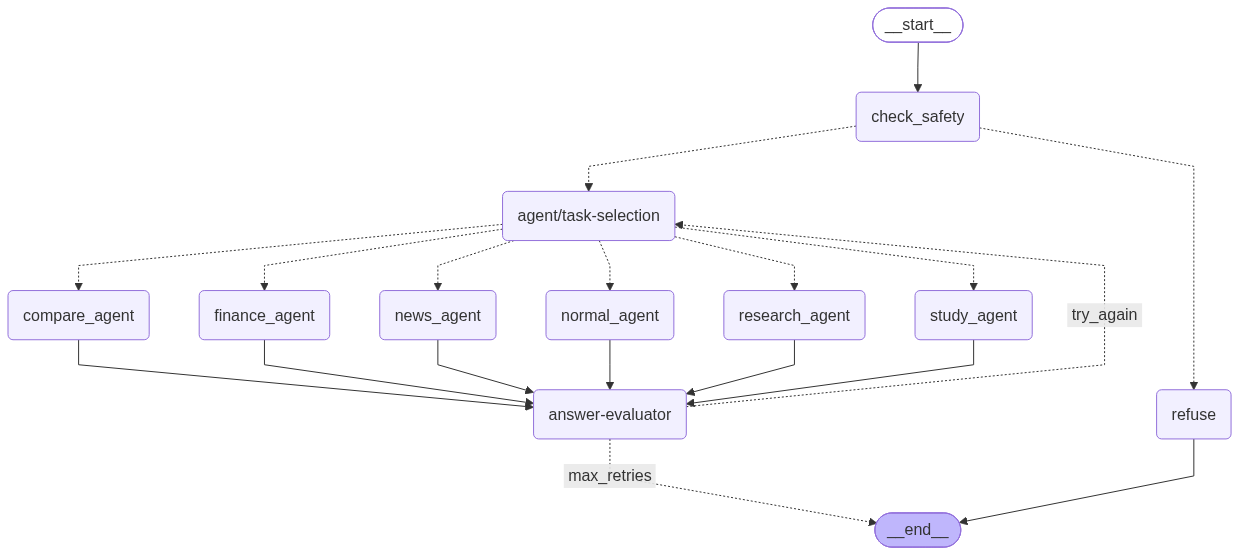

In [ ]:
checkpointer=InMemorySaver()
graph=StateGraph(OrcsAgent)

graph.add_node("check_safety",safety)
graph.add_node("agent/task-selection",orcs_decison)
graph.add_node("research_agent",research_node)
graph.add_node("finance_agent",finance_node)
graph.add_node("study_agent",study_node)
graph.add_node("compare_agent",compare_node)
graph.add_node("news_agent",news_node)
graph.add_node("normal_agent",normal_node)
graph.add_node("answer-evaluator",answere_node)
graph.add_node("refuse",refuse_node)



graph.add_edge(START,"check_safety")
graph.add_conditional_edges("check_safety",route_safely)
graph.add_conditional_edges("agent/task-selection",which_agent)
for name in ["research_agent", "finance_agent", "study_agent", "compare_agent", "news_agent", "normal_agent"]:
    graph.add_edge(name, "answer-evaluator")

graph.add_conditional_edges(
    "answer-evaluator",
    route_evaluation,
    {"ok": END, "max_retries":END, "try_again": "agent/task-selection"},
)

graph.add_edge("refuse",END)

orchestrator=graph.compile(checkpointer=checkpointer)
orchestrator

In [ ]:

query = "Compare the pros and cons of Python and JavaScript for building a beginner web app"

initial_message = {'messages': [orcs_sp,HumanMessage(content=query)]}
response = orchestrator.invoke(initial_message, config=Config[6])

In [ ]:
response

{'messages': [SystemMessage(content='\nYou are an Orchestrator Agent.\nYour primary role is to analyze incoming user queries and route them to the single most appropriate specialized agent, or sequence of agents.\n\nFollow these routing rules carefully:\n\n1. RESEARCH AGENT:\n   - Assign if the user query requires in-depth analysis, technical explanations, background documentation, or detailed topic exploration.\n\n2. FINANCE AGENT:\n   - Assign if the query involves budgeting, stock markets, crypto, investments, financial planning, banking, tax, or economic data.\n\n3. STUDY AGENT:\n   - Assign if the query involves educational topics, learning materials, explanations for students, test preparation, homework help, or academic guidance.\n\n4. COMPARE AGENT:\n   - Assign if the query explicitly asks to evaluate, contrast, pros/cons, or pit two or more items, options, products, or technologies against each other.\n\n5. NEWS AGENT:\n   - Assign if the query asks about current events, brea

In [ ]:
print("USER QUERY:  ",response['query'],'\n\nAgent Response: ',response['agent_response'])

USER QUERY:   Compare the pros and cons of Python and JavaScript for building a beginner web app 

Agent Response:  Here’s a concise comparison of **Python vs. JavaScript** for building a **beginner web app**:

## Python
**Pros**
- Easier to read and learn for many beginners
- Great for backend development with frameworks like **Django** or **Flask**
- Clean syntax, often simpler for logic-heavy apps
- Strong ecosystem for data handling, automation, and APIs

**Cons**
- Not used for frontend in the browser
- Requires pairing with HTML/CSS and usually some JavaScript anyway for interactive UI
- Less “full-stack in one language” than JavaScript

## JavaScript
**Pros**
- Runs in the browser, so it covers the frontend naturally
- Can also be used on the backend with **Node.js**
- Best choice if you want one language across frontend and backend
- Huge ecosystem for web development and UI libraries

**Cons**
- Can feel messy to beginners because of many frameworks and patterns
- Syntax and a